## Workshop 3: Segmentación de clientes con Clustering (K-Means vs. Agglomerative vs. DBSCAN)

In [117]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("./data/Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [118]:
df.shape

(200, 5)

In [119]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [120]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [122]:
df.drop(columns=["CustomerID"], inplace=True)
#2.2

In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  200 non-null    object
 1   Age                     200 non-null    int64 
 2   Annual Income (k$)      200 non-null    int64 
 3   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 6.4+ KB


Otro

In [124]:
#2.3
# Codificación One-Hot de Gender (drop='first' deja solo Gender_Male)
encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded_array = encoder.fit_transform(df[['Gender']])

df_encoded = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(['Gender']),
    dtype=int,
    index=df.index,
)

# Reemplazamos la columna original por la codificada
df = pd.concat([df.drop(columns=['Gender']), df_encoded], axis=1)

In [125]:
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


In [126]:
features = ["Gender_Male", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

Fase 3

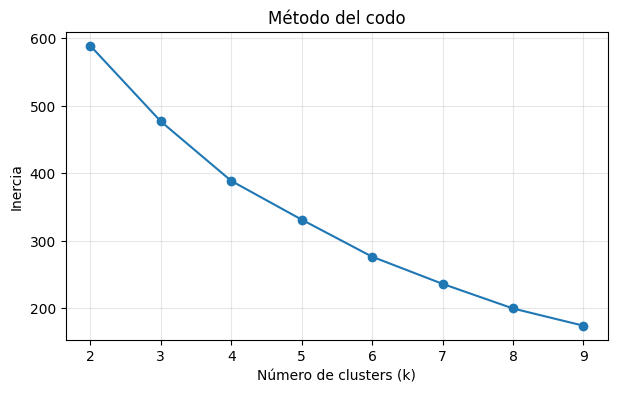

In [127]:
import matplotlib.pyplot as plt

inertias = []
ks = range(2, 10)

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

In [128]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


results = []

for k, inertia in zip(ks, inertias):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    results.append({
        "k": k,
        "Inercia": inertia,
        "Silhouette Score": silhouette_score(X_scaled, labels_k),
    })

df_kmeans = pd.DataFrame(results).set_index("k")
df_kmeans.round(4)


,Inercia,Silhouette Score
k,,
2,588.8027,0.2518
3,476.7876,0.2595
4,388.7179,0.2984
5,331.3099,0.3041
6,276.4118,0.3311
7,236.2049,0.3574
8,199.7505,0.3880
9,174.2355,0.4031


In [ ]:
# K-Means

k=6
model = KMeans(
    n_clusters=k,     
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X_scaled)